# Configure the .env

In [1]:
import os
from dotenv import load_dotenv
from getpass import getpass

try:
    load_dotenv()
except Exception as e:
    pass

if not os.getenv("NVIDIA_API_KEY"):
    os.environ["NVIDIA_API_KEY"] = getpass("Enter your NVIDIA API key: ")

if not os.getenv("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"] = getpass("Enter your TAVILY API key: ")
    
if not os.getenv("PINECONE_API_KEY"):
    os.environ["PINECONE_API_KEY"] = getpass("Enter your PINECONE API key: ")
    
    
print("NVIDIA_API_KEY configured:", bool(os.getenv("NVIDIA_API_KEY")))
print("TAVILY_API_KEY configured:", bool(os.getenv("TAVILY_API_KEY")))
print("PINECONE_API_KEY configured:", bool(os.getenv("PINECONE_API_KEY")))


NVIDIA_API_KEY configured: True
TAVILY_API_KEY configured: True
PINECONE_API_KEY configured: True


# Loading the document

In [2]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader("company_policy_manual.pdf")

docs = loader.load()

print(docs[0].page_content[:500])  # Print the first 500 characters of the first page

C:\Users\Abhi\AppData\Local\Temp\ipykernel_11068\3788810399.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/KLQRNP+Times-Roman', '/FontDescriptor': IndirectObject(10, 0, 1520803263120), '/Type': '/Font', '/FirstChar': 32, '/LastChar': 95, '/Widths': [250, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 500], '/Encoding': '/WinAnsiEncoding', '/Subtype': '/Type1'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the enc

FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE  
__________________________________________________________________________________  
 
__________________________________________________________________________________ 
 
MD ACCOUNTANTS & AUDITORS INC.         - 1 -  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
COMPANY POLICY MANUAL  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
As per your Letter of Appointment and Employment Contracts, this Company Policy Manual is to be read and 
signed prior to the commencement of y


In [3]:
# Separate the pages
pages = [doc for doc in docs if doc.metadata.get("page") is not None]
print(f"Total pages loaded: {len(pages)}")

Total pages loaded: 43


In [4]:
#  each page needs a source_id and page_number for better tracking and retrieval. Let's add those attributes to each page's metadata.
if not pages:
    raise ValueError("No pages found in the document. Please check the PDF file.")


# generate a unique doc_id for each page based on the document name and page number
doc_id = "company_policy_manual"
page_records = [
    {
        "doc_id": doc_id,
        "source_name": "MD ACCOUNTANTS & AUDITORS INC.",
        "page_number": page_num,
        "content": page.page_content,
    }
    for page_num, page in enumerate(pages, start=1)
]

print(f"Created {len(page_records)} page records.")

print(f"first page metadata:", {k: v for k, v in page_records[1].items() if k != "content"})
print(f"first page content preview:", page_records[0]["content"][:500])  # Print the first 500 characters of the first page's content

Created 43 page records.
first page metadata: {'doc_id': 'company_policy_manual', 'source_name': 'MD ACCOUNTANTS & AUDITORS INC.', 'page_number': 2}
first page content preview: FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE  
__________________________________________________________________________________  
 
__________________________________________________________________________________ 
 
MD ACCOUNTANTS & AUDITORS INC.         - 1 -  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
COMPANY POLICY MANUAL  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
As per your Letter of Appointment and Employment Contracts, this Company Policy Manual is to be read and 
signed prior to the commencement of y


In [5]:
# Analyse the contents through samples (for checking section heading and content structure)

samples = [
    
    (record, [line.strip() for line in record["content"].splitlines() if line.strip()])
    for record in page_records if record.get("content").strip()
    
][:5]  # Limit to first 5 samples for brevity

for record, lines in samples:
    print("\n".join(lines[:5]))  # Print first 5 lines of content for each sample


FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE
__________________________________________________________________________________
__________________________________________________________________________________
MD ACCOUNTANTS & AUDITORS INC.         - 1 -
COMPANY POLICY MANUAL
FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE
__________________________________________________________________________________
__________________________________________________________________________________
MD ACCOUNTANTS & AUDITORS INC.         - 2 -
INDEX
FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE
__________________________________________________________________________________
__________________________________________________________________________________
MD ACCOUNTANTS & AUDITORS INC.         - 3 -
9.16 Computer Assistance
FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE
__________________________________________________________________________________
___________________

PDF page 4:


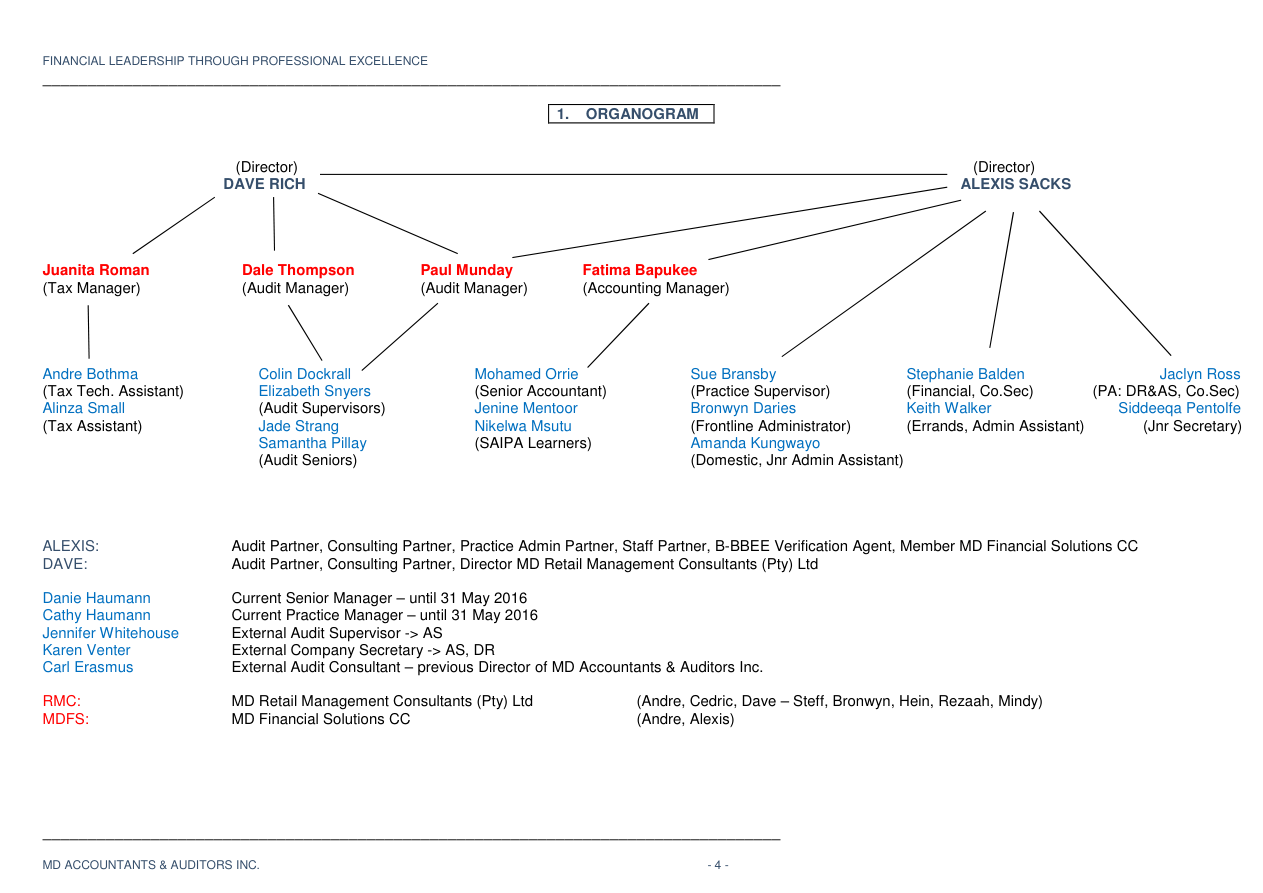

PDF page 5:


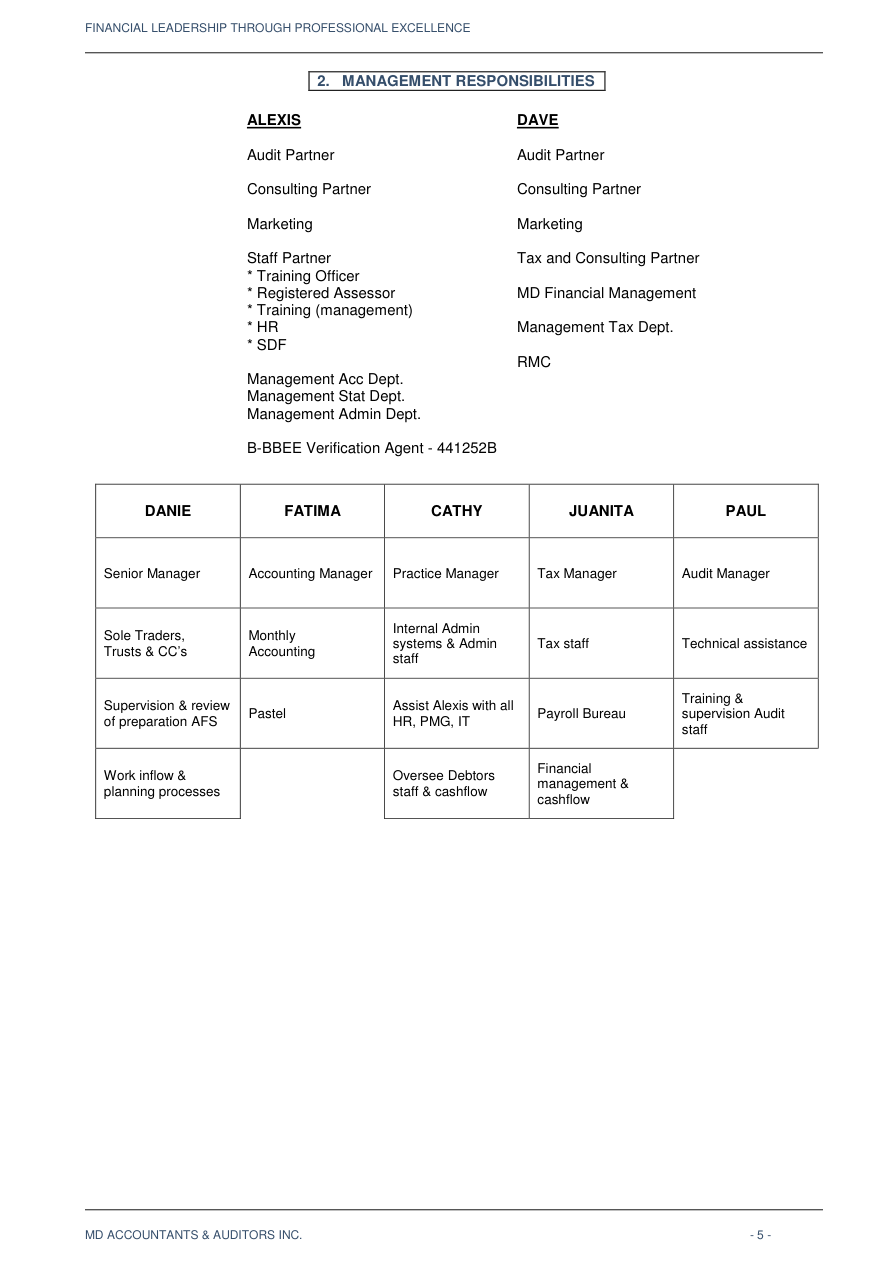

In [6]:
# Here, page 4 and 5 have graphs and 
# tables, and normal text extraction 
# might not work well. 
# lets render the PDF pages as images and use OCR to extract text from those images.

import importlib.util
from IPython.display import display, Image

if importlib.util.find_spec("pymupdf"):
    import pymupdf as pdf_renderer
elif importlib.util.find_spec("fitz"):
    import fitz as pdf_renderer
else:
    pdf_renderer = None

if pdf_renderer is None:
    print("No PyMuPDF renderer found.")
else:
    pdf_doc = pdf_renderer.open(
        stream=open("company_policy_manual.pdf", "rb").read(),
        filetype="pdf",
    )
    for page_number in (4, 5):
        page = pdf_doc[page_number - 1]
        pix = page.get_pixmap(
            matrix=pdf_renderer.Matrix(1.5, 1.5),
            alpha=False,
        )
        print(f"PDF page {page_number}:")
        display(Image(data=pix.tobytes("png")))



In [7]:
# Seeing if the text extraction from the images works better than the normal text extraction for pages 4 and 5.


records_by_page = {r["page_number"]: r for r in page_records}

for page_number in (5, 6):
    content = records_by_page[page_number].get("content", "")
    print(f"\n--- PDF page {page_number} ({len(content)} characters) ---")
    print(content[:1600] if content.strip() else "[No text extracted]")


--- PDF page 5 (1304 characters) ---
FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE  
__________________________________________________________________________________  
 
__________________________________________________________________________________ 
 
MD ACCOUNTANTS & AUDITORS INC.         - 5 -  
2.   MANAGEMENT RESPONSIBILITIES  
 
    ALEXIS    DAVE     
 
    Audit Partner    Audit Partner 
 
    Consulting Partner   Consulting Partner 
 
    Marketing    Marketing 
      
    Staff Partner    Tax and Consulting Partner 
   * Training Officer 
   * Registered Assessor   MD Financial Management   
    * Training (management)     
    * HR     Management Tax Dept.   
   * SDF      
        RMC 
   Management Acc Dept.         
   Management Stat Dept.        
    Management Admin Dept. 
 
   B-BBEE Verification Agent - 441252B      
    
  
  
DANIE FATIMA CATHY JUANITA PAUL 
Senior Manager Accounting Manager Practice Manager Tax  Manager Audit Manager 
Sole Traders,  


# Splitting the documents

In [8]:
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

documents = [
    Document(
        page_content=page['content'],
        metadata={
            "doc_id": page['doc_id'],
            "source_name": page['source_name'],
            "page_number": page['page_number'],
        }
    )
    
    for page in page_records
]

splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=100,
    add_start_index=True,
)

chunks = splitter.split_documents(documents)
print(f"Total chunks created: {len(chunks)}")
print(f"First chunk metadata: {chunks[0].metadata}")
print(f"First chunk content preview: {chunks[0].page_content[:500]}")  # Print the first 500 characters of the first chunk


Total chunks created: 296
First chunk metadata: {'doc_id': 'company_policy_manual', 'source_name': 'MD ACCOUNTANTS & AUDITORS INC.', 'page_number': 1, 'start_index': 0}
First chunk content preview: FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE  
__________________________________________________________________________________  
 
__________________________________________________________________________________ 
 
MD ACCOUNTANTS & AUDITORS INC.         - 1 -  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
COMPANY POLICY MANUAL  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
As per your Letter of Appointment and Employment Contracts, this Company Policy Manual is to be read and


In [9]:
# adding section by page metadata to each chunk based on the page number. 
# This will help in categorizing the chunks according to their respective sections in the document.

from collections import Counter

section_by_page = {
    1: "Cover",
    2: "Index",
    4: "Organogram",
    5: "Management Responsibilities",
}

for doc in chunks:
    page = int(doc.metadata["page_number"])
    doc.metadata["section_title"] = section_by_page.get(page, "Unclassified")

print("Chunk labels:", dict(Counter(doc.metadata["section_title"] for doc in chunks)))

Chunk labels: {'Cover': 3, 'Index': 4, 'Unclassified': 279, 'Organogram': 6, 'Management Responsibilities': 4}


In [10]:
print(chunks[0].metadata)

{'doc_id': 'company_policy_manual', 'source_name': 'MD ACCOUNTANTS & AUDITORS INC.', 'page_number': 1, 'start_index': 0, 'section_title': 'Cover'}


In [11]:
# Checking content

index_chunks = [
    doc for doc in chunks
    if int(doc.metadata["page_number"]) == 2
]

for doc in index_chunks:
    print(doc.page_content)

FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE  
__________________________________________________________________________________  
 
__________________________________________________________________________________ 
 
MD ACCOUNTANTS & AUDITORS INC.         - 2 -  
INDEX 
 
1. Organogram 
 
2. Management Responsibilities 
 
3. Definitions 
 
4. Code of Conduct  
4.1 Rules of Professional Conduct and Quality Contr ol 
4.2 Money Laundering Control 
 
5. Contractual Responsibilities
4.2 Money Laundering Control 
 
5. Contractual Responsibilities 
5.1 Secrecy and Non-Disclosure 
5.2 Restraint of Trade 
 5.3 Electronic Communications  
 
6. Conditions of Employment 
6.1 Office Hours 
6.2 Overtime 
6.3 Study Leave 
6.4 Annual Leave 
6.5 Sick Leave 
6.6 Maternity Leave 
6.7 Family Responsibility Leave 
6.8 Academic Progress 
6.9 Training Courses 
6.10 References and Security Checks 
 
7. Remuneration Package 
7.1 Remuneration 
  7.1.1 Gross Remuneration 
7.1.2 Cash Component
7. Remun

In [12]:
# locating section headings in the document based on the index page and 
# the content of the pages. This will help in identifying the structure 
# of the document and facilitate better navigation through the content.

import re

heading_candidates = set()

for doc in chunks:
    page = int(doc.metadata["page_number"])

    # Skip the index page, where headings are listed without body sections.
    if page == 2:
        continue

    for line in doc.page_content.splitlines():
        line = " ".join(line.split())
        match = re.match(r"^(\d{1,2})\.\s+(.{3,80})$", line)
        if not match:
            continue

        title = match.group(2).strip()
        letters = [char for char in title if char.isalpha()]
        if not letters:
            continue

        uppercase_ratio = sum(char.isupper() for char in letters) / len(letters)
        title_case = all(
            word[0].isupper()
            for word in title.split()
            if word and word[0].isalpha()
        )

        if uppercase_ratio >= 0.8 or (len(title.split()) <= 7 and title_case):
            heading_candidates.add((page, f"{match.group(1)}. {title}"))

for page, heading in sorted(heading_candidates):
    print(f"PDF page {page}: {heading}")

PDF page 3: 13. Contractual Provisions
PDF page 4: 1. ORGANOGRAM
PDF page 5: 2. MANAGEMENT RESPONSIBILITIES
PDF page 6: 3. DEFINITIONS
PDF page 7: 4. CODE OF CONDUCT
PDF page 8: 5. CONTRACTUAL RESPONSIBILITIES
PDF page 12: 6. CONDITION S OF EMPLOYMENT
PDF page 17: 7. REMUNERATION PACKAGE
PDF page 21: 8. COMPANY BENEFITS
PDF page 22: 9. COMPANY POLICIES
PDF page 30: 10. SECURITY AND SAFETY GUIDELINES
PDF page 31: 11. TERMINATION OF EMPLOYMENT
PDF page 35: 12. GR IEVANCE & DISCIPLINARY PROCEDURES
PDF page 38: 13. CONTRACTUAL PROVISIONS
PDF page 39: 1. Absenteeism
PDF page 39: 2. Desertion
PDF page 40: 1. Rationale
PDF page 40: 2. The Dangers
PDF page 41: 10. Grievances
PDF page 41: 12. Budget
PDF page 41: 7. Discrimination
PDF page 41: 9. Transparency


In [13]:
from bisect import bisect_right
from collections import Counter

section_starts = [
    (4, "Organogram"),
    (5, "Management Responsibilities"),
    (6, "Definitions"),
    (7, "Code of Conduct"),
    (8, "Contractual Responsibilities"),
    (12, "Conditions of Employment"),
    (17, "Remuneration Package"),
    (21, "Company Benefits"),
    (22, "Company Policies"),
    (30, "Security and Safety Guidelines"),
    (31, "Termination of Employment"),
    (35, "Grievance & Disciplinary Procedures"),
    (38, "Contractual Provisions"),
]
start_pages = [page for page, _ in section_starts]

for doc in chunks:
    page = int(doc.metadata["page_number"])

    if page == 1:
        section_title = "Cover"
    elif page in (2, 3):
        section_title = "Index"
    else:
        section_index = bisect_right(start_pages, page) - 1
        section_title = section_starts[section_index][1]

    doc.metadata["section_title"] = section_title

print("Chunk labels:", dict(Counter(doc.metadata["section_title"] for doc in chunks)))

Chunk labels: {'Cover': 3, 'Index': 7, 'Organogram': 6, 'Management Responsibilities': 4, 'Definitions': 4, 'Code of Conduct': 3, 'Contractual Responsibilities': 33, 'Conditions of Employment': 41, 'Remuneration Package': 30, 'Company Benefits': 4, 'Company Policies': 59, 'Security and Safety Guidelines': 8, 'Termination of Employment': 27, 'Grievance & Disciplinary Procedures': 21, 'Contractual Provisions': 46}


# Embedding model

In [14]:
from langchain_ollama import OllamaEmbeddings

embeddings = OllamaEmbeddings(
    model="nomic-embed-text"
)


# Preparing vector store

In [15]:
from pinecone import Pinecone, ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import time

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag_v1"

# Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Create the index only if it does not already exist.
existing_indexes = [index_info["name"] for index_info in pc.list_indexes()]

if INDEX_NAME not in existing_indexes:
    pc.create_index(
        name=INDEX_NAME,
        dimension=768,      
        metric="cosine",
        spec=ServerlessSpec(
            cloud="aws",
            region="us-east-1",
        ),
    )

    # Wait until Pinecone reports the new index as ready.
    while not pc.describe_index(INDEX_NAME).status["ready"]:
        time.sleep(1)

print("Pinecone index ready:", INDEX_NAME)
chunk_ids = [f"company-policy-chunk-{i}" for i in range(len(chunks))]
# Upload the document chunks and create the LangChain vector store.
vectorstore = PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    ids=chunk_ids,
    index_name=INDEX_NAME,
    namespace=NAMESPACE,
)

retriever = vectorstore.as_retriever(
    search_kwargs={
        "k": 8,
        "namespace": NAMESPACE,
    }
)

print("Pinecone vector database and retriever are ready.")

c:\Developer\Enterprise AI assistant\assistant_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pinecone index ready: industry-agentic-rag-kb
Pinecone vector database and retriever are ready.


In [16]:
# Load Existing Index

from pinecone import Pinecone
from langchain_pinecone import PineconeVectorStore

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag_v1"

# Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Load existing Pinecone index
index = pc.Index(INDEX_NAME)

# Connect existing index with LangChain
vectorstore = PineconeVectorStore(
    index=index,
    embedding=embeddings,
    namespace=NAMESPACE,
    
)

# Create retriever
retriever = vectorstore.as_retriever(
    search_kwargs={
        "k": 8,
        "namespace": NAMESPACE,
    }
)

print("Existing Pinecone index loaded:", INDEX_NAME)

Existing Pinecone index loaded: industry-agentic-rag-kb


In [17]:
embedding_dimension = len(embeddings.embed_query("dimension check"))
index_dimension = pc.describe_index(INDEX_NAME).dimension

print("Embedding dimension:", embedding_dimension)
print("Pinecone index dimension:", index_dimension)
print("Dimensions match:", embedding_dimension == index_dimension)

Embedding dimension: 768
Pinecone index dimension: 768
Dimensions match: True


In [18]:
index_stats = pc.Index(INDEX_NAME).describe_index_stats()
namespace_stats = index_stats.namespaces.get(NAMESPACE)
stored_vector_count = namespace_stats.vector_count if namespace_stats else 0

print("Current chunks:", len(chunks))
print("Current chunk pages:", sorted({doc.metadata.get("page_number") for doc in chunks}))
print("Vectors in Pinecone namespace:", stored_vector_count)

Current chunks: 296
Current chunk pages: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43]
Vectors in Pinecone namespace: 296


In [19]:
query = "What are the company's policies on electronic communications?"
retrieved_docs = retriever.invoke(query)
print(f"Retrieved {len(retrieved_docs)} documents for query: '{query}'")
print(retrieved_docs[0].page_content)  # Print the metadata of the first retrieved document

Retrieved 8 documents for query: 'What are the company's policies on electronic communications?'
covenants freely and voluntarily and that such restraint of trade covenants will not cause you any hardship 
which you are not willing to bear in return for the benefits offered by MD. 
 
 
5.3   ELECTRONIC COMMUNICATIONS 
 
The purpose of this policy is to optimise the effectiveness of the company’s electronic and communications 
systems, to minimise damage to and abuse of the Company’s facilities and to eliminate unnecessary costs


In [20]:
from langchain_ollama import ChatOllama

groq = ChatOllama(
    model="llama3.2"
)

In [21]:
prompt = "who is the founder of Apple company?"
response = groq.invoke(prompt)
print(repr(response.content))
print(response.additional_kwargs)

'The co-founders of Apple Inc. are:\n\n1. Steve Jobs\n2. Steve Wozniak\n\nHowever, the company was originally founded by Steve Jobs, Steve Wozniak, and Ronald Wayne in April 1976. Ronald Wayne sold his 10% stake in the company back to Jobs and Wozniak just a few months later, in July 1976.'
{}


In [22]:
model_response = groq.invoke("who is the founder of Apple company?")
print(model_response.content)

The founder of Apple Inc. is Steve Jobs (1955-2011), along with Steve Wozniak and Ronald Wayne. However, if you're looking for the original founders of the company, it's often referred to as Apple Computer, Inc., which was founded by:

1. Steve Wozniak (born 1950)
2. Ronald Wayne (born 1934) - sold his 10% stake in the company back to Jobs and Wozniak for $800 just a few months after its founding.

Steve Jobs, however, is often credited with the majority of the company's success, and is widely regarded as the driving force behind Apple's transformation into the technology giant it is today.


In [23]:
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate
from langchain_classic.chains import create_retrieval_chain
from langchain_classic.chains.combine_documents import create_stuff_documents_chain
from langchain_classic.retrievers.multi_query import MultiQueryRetriever

document_prompt = PromptTemplate.from_template(
    "[section:{section_title} | page_number: {page_number}]\n content: {page_content}"
    
)

prompt = ChatPromptTemplate([
    ("system", 
     """ You are an Enterprise AI assistant.
     "Answer from the given company policy manual document and provide the answer in a concise manner.
     "if you don't find the answer in the document, say "it is not present in this document in a polite manner."
     "Don't make your own answer if the answer is not present in the document.
     "Don't entertain questions not related to company until and unless it is normal talk like greetings or salutaions\n\n
     context: {context}
     """
     ),
    
    ("human", "{input}"),
])
multi_query_retriever = MultiQueryRetriever.from_llm(
    retriever=retriever,
    llm=groq,
    include_original=True,
)

answer_chain = create_stuff_documents_chain(
    llm = groq,
    prompt = prompt,
    document_prompt = document_prompt
)

rag_chain = create_retrieval_chain(
    multi_query_retriever,
    answer_chain,
)

In [24]:
sick_query = "What are the company's policies on transporation and travel for employees?"

rag_response = rag_chain.invoke({"input": sick_query})
print(rag_response["answer"])  # Print the content of the response

According to the document, the company's policies on transportation and travel for employees are as follows:

* The company will reimburse employees for reasonable travel expenses for business purposes, including transportation costs.
* The company has specific policies on parking reimbursement, including the requirement that no parking costs will be reimbursed without prior approval from the relevant Partner.
* Employees are expected to maintain a reasonable distance from the workplace to be eligible for reimbursement of travel expenses.
* Employees who are more than 6 staff members but not exceeding 9 will have access to company vehicles for business purposes.
* Employees are required to follow the company's rules on using company vehicles, including the requirement to obtain prior approval for the use of a personal vehicle.
* Employees will be charged for any additional mileage incurred while using a personal vehicle, and will not be entitled to claim standard reimbursement costs.
*

In [25]:
retrieval_eval_set = [
    {
        "query": "What does the policy say about sick leave and medical leave?",
        "relevant_pages": {15},
    },
    {
        "query": "Summarize the reporting structure shown in the Organogram.",
        "relevant_pages": {4},
    },
    {
        "query": "What are the main responsibilities assigned to management?",
        "relevant_pages": {5},
    },
]

print(f"Evaluation questions: {len(retrieval_eval_set)}")
for item in retrieval_eval_set:
    print(item)

Evaluation questions: 3
{'query': 'What does the policy say about sick leave and medical leave?', 'relevant_pages': {15}}
{'query': 'Summarize the reporting structure shown in the Organogram.', 'relevant_pages': {4}}
{'query': 'What are the main responsibilities assigned to management?', 'relevant_pages': {5}}


In [26]:
dense_retriever = vectorstore.as_retriever(
    search_kwargs={"k": 8, "namespace": NAMESPACE}
)

dense_results = []

for item in retrieval_eval_set:
    docs = dense_retriever.invoke(item["query"])
    ranked_pages = list(dict.fromkeys(
        int(doc.metadata["page_number"])
        for doc in docs
        if doc.metadata.get("page_number") is not None
    ))
    relevant = item["relevant_pages"]
    relevant_ranks = [
        rank for rank, page in enumerate(ranked_pages, start=1)
        if page in relevant
    ]
    dense_results.append({
        "query": item["query"],
        "pages": ranked_pages,
        "hit": int(bool(relevant_ranks)),
        "recall": len(set(ranked_pages) & relevant) / len(relevant),
        "mrr": 1 / relevant_ranks[0] if relevant_ranks else 0.0,
    })
    print(f"Query: {item['query']}\nPages @8: {ranked_pages}")

count = len(dense_results)
print(
    f"\nDense @8 — Hit Rate: {sum(r['hit'] for r in dense_results) / count:.2f} | "
    f"Recall: {sum(r['recall'] for r in dense_results) / count:.2f} | "
    f"MRR: {sum(r['mrr'] for r in dense_results) / count:.2f}"
)

Query: What does the policy say about sick leave and medical leave?
Pages @8: [14, 15, 13]
Query: Summarize the reporting structure shown in the Organogram.
Pages @8: [41, 15, 17, 30, 25, 7]
Query: What are the main responsibilities assigned to management?
Pages @8: [22, 30, 25, 31, 6, 8]

Dense @8 — Hit Rate: 0.33 | Recall: 0.33 | MRR: 0.17


In [27]:
from langchain_community.retrievers import BM25Retriever

bm25_retriever = BM25Retriever.from_documents(chunks, k=8)
bm25_results = []

for item in retrieval_eval_set:
    docs = bm25_retriever.invoke(item["query"])
    ranked_pages = list(dict.fromkeys(
        int(doc.metadata["page_number"])
        for doc in docs
        if doc.metadata.get("page_number") is not None
    ))
    relevant = item["relevant_pages"]
    relevant_ranks = [
        rank for rank, page in enumerate(ranked_pages, start=1)
        if page in relevant
    ]
    bm25_results.append({
        "hit": int(bool(relevant_ranks)),
        "recall": len(set(ranked_pages) & relevant) / len(relevant),
        "mrr": 1 / relevant_ranks[0] if relevant_ranks else 0.0,
    })
    print(f"Query: {item['query']}\nPages @8: {ranked_pages}")

count = len(bm25_results)
print(
    f"\nBM25 @8 — Hit Rate: {sum(r['hit'] for r in bm25_results) / count:.2f} | "
    f"Recall: {sum(r['recall'] for r in bm25_results) / count:.2f} | "
    f"MRR: {sum(r['mrr'] for r in bm25_results) / count:.2f}"
)

Query: What does the policy say about sick leave and medical leave?
Pages @8: [41, 15, 14, 37]
Query: Summarize the reporting structure shown in the Organogram.
Pages @8: [17, 39, 35, 28, 30, 42]
Query: What are the main responsibilities assigned to management?
Pages @8: [24, 20, 31, 25, 35, 26, 40]

BM25 @8 — Hit Rate: 0.33 | Recall: 0.33 | MRR: 0.17


In [28]:
from langchain_classic.retrievers.ensemble import EnsembleRetriever

hybrid_retriever = EnsembleRetriever(
    retrievers=[dense_retriever, bm25_retriever],
    weights=[0.5, 0.5],
)

hybrid_results = []

for item in retrieval_eval_set:
    docs = hybrid_retriever.invoke(item["query"])[:8]
    ranked_pages = list(dict.fromkeys(
        int(doc.metadata["page_number"])
        for doc in docs
        if doc.metadata.get("page_number") is not None
    ))
    relevant = item["relevant_pages"]
    relevant_ranks = [
        rank for rank, page in enumerate(ranked_pages, start=1)
        if page in relevant
    ]
    hybrid_results.append({
        "hit": int(bool(relevant_ranks)),
        "recall": len(set(ranked_pages) & relevant) / len(relevant),
        "mrr": 1 / relevant_ranks[0] if relevant_ranks else 0.0,
    })
    print(f"Query: {item['query']}\nPages @8: {ranked_pages}")

count = len(hybrid_results)
print(
    f"\nHybrid @8 — Hit Rate: {sum(r['hit'] for r in hybrid_results) / count:.2f} | "
    f"Recall: {sum(r['recall'] for r in hybrid_results) / count:.2f} | "
    f"MRR: {sum(r['mrr'] for r in hybrid_results) / count:.2f}"
)

Query: What does the policy say about sick leave and medical leave?
Pages @8: [15, 14, 41, 37]
Query: Summarize the reporting structure shown in the Organogram.
Pages @8: [17, 41, 15, 39, 30, 35]
Query: What are the main responsibilities assigned to management?
Pages @8: [22, 24, 30, 20, 25, 31]

Hybrid @8 — Hit Rate: 0.33 | Recall: 0.33 | MRR: 0.33


In [29]:
from langchain_classic.retrievers.self_query.base import SelfQueryRetriever
from langchain_classic.chains.query_constructor.schema import AttributeInfo
from langchain_community.query_constructors.pinecone import PineconeTranslator

section_info = AttributeInfo(
    name="section_title",
    description=(
        "Top-level manual section. Values include Organogram, "
        "Management Responsibilities, Conditions of Employment, "
        "Company Policies, and Contractual Responsibilities. "
        "Organizational structure questions map to Organogram."
    ),
    type="string",
)

self_query_llm = ChatOllama(
    model="llama3.2",
    temperature=0,
    format="json",
)

self_query_retriever = SelfQueryRetriever.from_llm(
    llm=self_query_llm,
    vectorstore=vectorstore,
    document_contents="Chunks from the company policy manual.",
    metadata_field_info=[section_info],
    structured_query_translator=PineconeTranslator(),
    chain_kwargs={
        "examples": [
            (
                "What does the policy say about sick leave and medical leave?",
                {
                    "query": "sick leave medical leave",
                    "filter": 'eq("section_title", "Conditions of Employment")',
                },
            ),
            (
                "Summarize the reporting structure shown in the Organogram.",
                {
                    "query": "reporting structure",
                    "filter": 'eq("section_title", "Organogram")',
                },
            ),
        ],
    },
    search_kwargs={"k": 8, "namespace": NAMESPACE},
)

organogram_query = "Summarize the reporting structure shown in the Organogram."

organogram_docs = vectorstore.similarity_search(
    organogram_query,
    k=8,
    namespace=NAMESPACE,
    filter={
        "section_title": {
            "$eq": "Organogram"
        }
    },
)

if not organogram_docs:
    organogram_docs = retriever.invoke(organogram_query)

for doc in organogram_docs:
    print(
        f"page={doc.metadata.get('page_number')} "
        f"section={doc.metadata.get('section_title')}"
    )
    print(doc.page_content[:400], "\n")

page=4.0 section=Organogram
FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE  
__________________________________________________________________________________  
 
__________________________________________________________________________________ 
 
MD ACCOUNTANTS & AUDITORS INC.         - 4 -  
1.     ORGANOGRAM  
     
         
     (Director)                       (Director)  
            DAVE RICH                  

page=4.0 section=Organogram
Juanita Roman            Dale Thompson   Paul Munday  Fatima Bapukee   
(Tax Manager)             (Audit Manager)             (Audit Manager)   (Acco unting Manager)                    
 
 
 
                                                         
Andre Bothma   Colin Dockrall   Mohamed Orrie   Sue  Bransby   Stephanie Balden                 Jaclyn Ross 

page=4.0 section=Organogram
(Tax Tech. Assistant)   Elizabeth Snyers  (Senior Accountant)   (Practice Supervisor)           (Financial, Co.Sec)              (PA: DR&AS, Co.Sec) 
Ali

In [30]:
test_queries = [
    "What does the policy say about sick leave and medical leave?",
    "Summarize the reporting structure shown in the Organogram.",
    "What are the main responsibilities assigned to management?",
]

for query in test_queries:
    try:
        docs = self_query_retriever.invoke(query)
    except Exception as exc:
        print(f"Self-query parsing failed; using standard retrieval: {exc}")
        docs = retriever.invoke(query)
    
    pages = list(dict.fromkeys(
        doc.metadata.get("page_number")
        for doc in docs
        if doc.metadata.get("page_number") is not None
    ))
    
    section_titles = list(dict.fromkeys(
        doc.metadata.get("section_title")
        for doc in docs
        if doc.metadata.get("section_title") is not None
    ))
    
    print(f"Query: {query}\nPages: {pages}\nSections: {section_titles}\n")

Query: What does the policy say about sick leave and medical leave?
Pages: [14.0, 15.0, 13.0]
Sections: ['Conditions of Employment']

Query: Summarize the reporting structure shown in the Organogram.
Pages: [4.0]
Sections: ['Organogram']

Query: What are the main responsibilities assigned to management?
Pages: [5.0]
Sections: ['Management Responsibilities']



In [31]:
self_query_rag_chain = create_retrieval_chain(
    self_query_retriever,
    answer_chain,
)

query = "What does the policy say about sick leave and medical leave?"
try:
    rag_response = self_query_rag_chain.invoke({"input": query})
except Exception as exc:
    print(f"Self-query parsing failed; using standard retrieval instead: {exc}")

    docs = retriever.invoke(query)
    answer = answer_chain.invoke({
        "input": query,
        "context": docs,
    })

    rag_response = {
        "input": query,
        "context": docs,
        "answer": answer,
    }

print(
    "Pages passed to answer chain:",
    list(dict.fromkeys(
        int(float(doc.metadata["page_number"]))
        for doc in rag_response["context"]
        if doc.metadata.get("page_number") is not None
    ))
)

print("Answer:", rag_response["answer"])


Pages passed to answer chain: [14, 15, 13]
Answer: According to the document, sick leave is for when you were supposed to be at work, but were unable to attend work because of ill-health or injury. To qualify for sick leave, you have to be sick and unable to work.

Here are some key points about sick leave and medical leave:

* Visits and check-ups to the dentist, doctor, gynaecologist, chemist, etc., do not count as sick leave when not sick.
* No sick leave will be granted in the termination period unless accompanied by a sick leave certificate that shows (twenty-six) days worked.
* The medical certificate must be signed by a medical practitioner or person who is certified to diagnose and treat patients and who is registered with a professional council.
* The medical certificate must be forwarded to MD within the first 48 hours of being off sick.
* The leave will be allocated first to annual leave and then to unpaid leave if there is insufficient leave available.


In [32]:
for query in [
    "Summarize the reporting structure shown in the Organogram.",
    "What are the main responsibilities assigned to management?",
]:
    result = self_query_rag_chain.invoke({"input": query})

    pages = list(dict.fromkeys(
        int(float(doc.metadata["page_number"]))
        for doc in result["context"]
    ))

    print(f"\nQuery: {query}")
    print(f"Pages passed to answer chain: {pages}")
    print("Answer:", result["answer"])


Query: Summarize the reporting structure shown in the Organogram.
Pages passed to answer chain: [4]
Answer: The Organogram shows the reporting structure for MD Accountants & Auditors Inc. It appears to have two main directors, Dave and Alexis Sacks.

Query: What are the main responsibilities assigned to management?
Pages passed to answer chain: [5]
Answer: According to the document, the main responsibilities assigned to management include: 

1. Work inflow & planning processes 
2. Oversee Debtors staff & cash flow 
3. Financial management & cash flow


In [33]:
query = "What are the main responsibilities assigned to management?"
result = self_query_rag_chain.invoke({"input": query})

print("Pages:", list(dict.fromkeys(
    int(float(doc.metadata["page_number"]))
    for doc in result["context"]
)))

for doc in result["context"]:
    print(f"\n--- Page {doc.metadata.get('page_number')} ---")
    print(doc.page_content[:700])

print("\nAnswer:\n", result["answer"])

Pages: [5]

--- Page 5.0 ---
FINANCIAL LEADERSHIP THROUGH PROFESSIONAL EXCELLENCE  
__________________________________________________________________________________  
 
__________________________________________________________________________________ 
 
MD ACCOUNTANTS & AUDITORS INC.         - 5 -  
2.   MANAGEMENT RESPONSIBILITIES  
 
    ALEXIS    DAVE     
 
    Audit Partner    Audit Partner 
 
    Consulting Partner   Consulting Partner 
 
    Marketing    Marketing

--- Page 5.0 ---
Work inflow & 
planning processes  Oversee Debtors staff & cashflow Financial management & cashflow

--- Page 5.0 ---
Consulting Partner   Consulting Partner 
 
    Marketing    Marketing 
      
    Staff Partner    Tax and Consulting Partner 
   * Training Officer 
   * Registered Assessor   MD Financial Management   
    * Training (management)     
    * HR     Management Tax Dept.   
   * SDF      
        RMC 
   Management Acc Dept.         
   Management Stat Dept.        
    Management Ad

In [34]:
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langchain_classic.chains.combine_documents import create_stuff_documents_chain

citation_prompt = ChatPromptTemplate.from_messages([
    ("system", """Answer using only the supplied context.
If the context does not support an answer, say so.
Cite factual claims with [PDF page N], using the page labels in the context.
Page labels may end in .0; cite the whole page number.
Do not infer reporting relationships or responsibilities unless the context supports them."""),
    ("human", "Question: {input}\n\nContext:\n{context}")
])

citation_document_prompt = PromptTemplate.from_template(
    "[PDF page {page_number} | Section: {section_title}]\n{page_content}"
)

citation_answer_chain = create_stuff_documents_chain(
    llm=groq,
    prompt=citation_prompt,
    document_prompt=citation_document_prompt,
)

citation_rag_chain = create_retrieval_chain(
    self_query_retriever,
    citation_answer_chain,
)

query = "What are the main responsibilities assigned to management?"
result = citation_rag_chain.invoke({"input": query})

print("Source pages:", list(dict.fromkeys(
    int(float(doc.metadata["page_number"]))
    for doc in result["context"]
)))
print("\nAnswer:\n", result["answer"])

Source pages: [5]

Answer:
 The main responsibilities assigned to management include:

1. Work inflow & planning processes
2. Overseeing Debtors staff and cash flow
3. Financial management and cash flow

These responsibilities are listed in the context on page 5.0, Section: Management Responsibilities.


In [35]:
citation_document_prompt = PromptTemplate.from_template(
    "[PDF page {page_number:.0f} | Section: {section_title}]\n{page_content}"
)

citation_answer_chain = create_stuff_documents_chain(
    llm=groq,
    prompt=citation_prompt,
    document_prompt=citation_document_prompt,
)

citation_rag_chain = create_retrieval_chain(
    self_query_retriever,
    citation_answer_chain,
)

query = "What does the policy say about sick leave and medical leave?"
result = citation_rag_chain.invoke({"input": query})

print("Source pages:", list(dict.fromkeys(
    int(float(doc.metadata["page_number"]))
    for doc in result["context"]
)))
print("\nAnswer:\n", result["answer"])

Source pages: [14, 15, 13]

Answer:
 According to the policy:

* You are entitled to 30 days paid sick leave over a 3-year period. 
* You are entitled to one day's paid sick leave for every 26 days worked during the first six months of continuous employment. 
* Visits and check-ups to the dentist, doctor, gynaecologist, chemist, etc., do not count as sick leave when not sick. 
* You must produce a medical certificate stating that you were unable to work due to illness or injury to qualify for sick leave. 
* The medical certificate must be signed by a medical practitioner or person who is certified to diagnose and treat patients and who is registered with a professional council. 
* The medical certificate must be forwarded to MD within the first 48 hours of being off sick.


In [36]:
citation_prompt = ChatPromptTemplate.from_messages([
    ("system", """Answer the user's question using only the supplied context.
Answer only what the question asks; leave out unrelated topics.
For organograms and diagrams, describe reporting relationships only when the source clearly shows them. Do not infer relationships from text order alone.
Cite factual statements as [PDF page N], using the page number shown in the context.
If the retrieved pages do not clarify something, say so and limit that statement to those pages."""),
    ("human", "Question: {input}\n\nContext:\n{context}")
])

citation_answer_chain = create_stuff_documents_chain(
    llm=groq,
    prompt=citation_prompt,
    document_prompt=citation_document_prompt,
)

citation_rag_chain = create_retrieval_chain(
    self_query_retriever,
    citation_answer_chain,
)

query = "What does the policy say about sick leave and medical leave?"

try:
    docs = self_query_retriever.invoke(query)
except Exception as exc:
    print(f"Self-query retrieval failed; using standard retrieval instead: {exc}")
    docs = retriever.invoke(query)

answer = citation_answer_chain.invoke({
    "input": query,
    "context": docs,
})

result = {
    "input": query,
    "context": docs,
    "answer": answer,
}

print("Source pages:", list(dict.fromkeys(
    int(float(doc.metadata["page_number"]))
    for doc in result["context"]
)))
print("\nAnswer:\n", result["answer"])

Source pages: [14, 15, 13]

Answer:
 The policy states that:

* You are entitled to 30 days paid sick leave over a 3-year period.
* You are entitled to one day's paid sick leave for every 26 days worked during the first six months of continuous employment.
* Visits and check-ups to the dentist, doctor, gynaecologist, chemist, etc., do not count as sick leave when not sick.
* You must provide a medical certificate stating why you were unable to work for the duration of your absence on account of sickness or injury to qualify for sick leave.
* Sick leave is for when you were supposed to be at work, but were unable to attend due to ill-health or injury.
* You must call your line-manager by 8:30am on the day of your absence to notify them that you are sick and to discuss any deadlines or urgent work.
* No sick leave will be granted in the termination period unless accompanied by a sick leave certificate that shows twenty-six days worked.
* You can be regarded as having used annual leave if

In [37]:
from typing_extensions import NotRequired, TypedDict
from langchain_core.documents import Document
from langgraph.graph import END, START, StateGraph

In [38]:
class RAGGraphState(TypedDict):
    input: str
    context: NotRequired[list[Document]]
    source_pages: NotRequired[list[int]]
    answer: NotRequired[str]
    
def retrieve_node(state: RAGGraphState) -> dict:
    result = self_query_retriever.invoke({"input": state["input"]})

    pages = list(dict.fromkeys(
        int(float(doc.metadata["page_number"]))
        for doc in result
        if doc.metadata.get("page_number") is not None
    ))

    return {
        "context": result,
        "source_pages": pages,
    }
    
def answer_node(state: RAGGraphState) -> dict:
    result = citation_answer_chain.invoke({
        "input": state["input"],
        "context": state.get("context", []),
        })
    
    return {
        "answer": result
    }
    

In [39]:
builder = StateGraph(RAGGraphState)

# adding nodes
builder.add_node("retrieve", retrieve_node)
builder.add_node("answer", answer_node)

# adding edges to the graph
builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "answer")
builder.add_edge("answer", END)

rag_graph = builder.compile()

result = rag_graph.invoke({
    "input": "What does the policy say about sick leave and medical leave?"
})

print("Source pages:", result.get("source_pages", []))
print("\nAnswer:\n", result['answer'])

Source pages: [14, 15, 13]

Answer:
 The policy does not provide a separate definition for medical leave, but rather combines it with sick leave in Section 6.5, which states that you are entitled to 30 days paid sick leave over a 3-year period. However, it does provide a separate section for maternity leave (Section 6.6), which outlines the entitlement to 4 consecutive months unpaid maternity leave.


In [40]:
from typing_extensions import NotRequired, TypedDict
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langchain_classic.chains.combine_documents import create_stuff_documents_chain
from langgraph.graph import END, START, StateGraph


class RAGGraphState(TypedDict):
    input: str
    context: NotRequired[list[Document]]
    source_pages: NotRequired[list[int]]
    retrieval_grade: NotRequired[str]
    answer: NotRequired[str]


grade_prompt = ChatPromptTemplate.from_messages([
    ("system", """Check whether the retrieved text contains evidence relevant to the question.
Reply with exactly YES if it contains relevant evidence, even if the evidence is partial.
Reply with exactly NO if it contains no relevant evidence."""),
    ("human", "Question: {input}\n\nRetrieved text:\n{context}")
])

retrieval_grade_chain = create_stuff_documents_chain(
    llm=groq,
    prompt=grade_prompt,
    document_prompt=PromptTemplate.from_template("{page_content}"),
    output_parser=StrOutputParser(),
)


def grade_node(state: RAGGraphState) -> dict:
    grade = retrieval_grade_chain.invoke({
        "input": state["input"],
        "context": state["context"],
    })
    return {"retrieval_grade": grade.strip().upper()}


builder = StateGraph(RAGGraphState)
builder.add_node("retrieve", retrieve_node)
builder.add_node("grade", grade_node)
builder.add_node("answer", answer_node)
builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "grade")
builder.add_edge("grade", "answer")
builder.add_edge("answer", END)

rag_graph = builder.compile()

graph_result = rag_graph.invoke({
    "input": "What does the policy say about sick leave and medical leave?"
})

print("Retrieval grade:", graph_result["retrieval_grade"])
print("Source pages:", graph_result["source_pages"])
print("\nAnswer:\n", graph_result["answer"])

Retrieval grade: YES
Source pages: [14, 15, 13]

Answer:
 According to the policy, you are entitled to 30 days of paid sick leave over a 3-year period. Additionally, during the first six months of continuous employment, you are entitled to one day's paid sick leave for every 26 days worked.


In [41]:
# Retrieval grade: (checker) YES if the retrieved text contains relevant evidence, even if partial. NO if it contains no relevant evidence.

from typing_extensions import NotRequired, TypedDict
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langchain_classic.chains.combine_documents import create_stuff_documents_chain
from langgraph.graph import END, START, StateGraph


class RAGGraphState(TypedDict):
    input: str
    context: NotRequired[list[Document]]
    source_pages: NotRequired[list[int]]
    retrieval_grade: NotRequired[str]
    search_query: NotRequired[str]
    retry_count: NotRequired[int]
    answer: NotRequired[str]


rewrite_prompt = ChatPromptTemplate.from_messages([
    ("system", """Rewrite the search query to improve retrieval from a company policy manual.
Use the original question and retrieved text to make the query more specific.
Return only the rewritten search query. Do not answer the question."""),
    ("human", """Original question: {input}
Current search query: {search_query}
Retrieved text:
{context}""")
])

rewrite_chain = create_stuff_documents_chain(
    llm=groq,
    prompt=rewrite_prompt,
    document_prompt=PromptTemplate.from_template("{page_content}"),
    output_parser=StrOutputParser(),
)


def retrieve_node(state: RAGGraphState) -> dict:
    query = state.get("search_query", state["input"])
    docs = self_query_retriever.invoke(query)
    pages = list(dict.fromkeys(
        int(float(doc.metadata["page_number"]))
        for doc in docs
    ))
    return {"context": docs, "source_pages": pages}


def grade_node(state: RAGGraphState) -> dict:
    grade = retrieval_grade_chain.invoke({
        "input": state["input"],
        "context": state["context"],
    })
    return {"retrieval_grade": grade.strip().upper()}


def route_after_grade(state: RAGGraphState) -> str:
    if state["retrieval_grade"].startswith("YES"):
        return "answer"
    if state.get("retry_count", 0) < 1:
        return "rewrite"
    return "answer"


def rewrite_node(state: RAGGraphState) -> dict:
    new_query = rewrite_chain.invoke({
        "input": state["input"],
        "search_query": state.get("search_query", state["input"]),
        "context": state["context"],
    }).strip()

    return {
        "search_query": new_query,
        "retry_count": state.get("retry_count", 0) + 1,
    }


def answer_node(state: RAGGraphState) -> dict:
    answer_text = citation_answer_chain.invoke({
        "input": state["input"],
        "context": state["context"],
    })
    return {"answer": answer_text}


builder = StateGraph(RAGGraphState)
builder.add_node("retrieve", retrieve_node)
builder.add_node("grade", grade_node)
builder.add_node("rewrite", rewrite_node)
builder.add_node("answer", answer_node)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "grade")
builder.add_conditional_edges(
    "grade",
    route_after_grade,
    {"answer": "answer", "rewrite": "rewrite"},
)
builder.add_edge("rewrite", "retrieve")
builder.add_edge("answer", END)

rag_graph = builder.compile()

graph_result = rag_graph.invoke({
    "input": "What does the policy say about sick leave and medical leave?"
})

print("Retrieval grade:", graph_result["retrieval_grade"])
print("Retry count:", graph_result.get("retry_count", 0))
print("Source pages:", graph_result["source_pages"])
print("\nAnswer:\n", graph_result["answer"])

Retrieval grade: YES
Retry count: 0
Source pages: [14, 15, 13]

Answer:
 According to the policy, here is what it says about sick leave and medical leave:

* You are entitled to 30 days paid sick leave over a 3-year period.
* To qualify for sick leave, you must be sick and unable to work.
* Visits and check-ups to the dentist, doctor, gynaecologist, chemist, etc. do not count as sick leave when not sick.
* You must produce a medical certificate stating why you were unable to work for the duration of your absence on account of sickness or injury.
* The medical certificate must be signed by a medical practitioner or person certified to diagnose and treat patients and registered with a professional council.
* The medical certificate must be forwarded to MD within the first 48 hours of being off sick.
* If you exceed the sick leave entitlement, sick leave will be regarded as annual or unpaid leave.
* No sick leave will be granted in the termination period unless accompanied by a sick leave

In [42]:
query = "What is the recipe for chocolate cake?"
result = rag_graph.invoke({"input": query})

print("Retrieval grade:", result["retrieval_grade"])
print("Retry count:", result.get("retry_count", 0))
print("Rewritten search query:", result.get("search_query"))
print("Source pages:", result["source_pages"])
print("\nAnswer:\n", result["answer"])

Retrieval grade: NO
Retry count: 1
Rewritten search query: What is the policy on employee sick leave including the required information on medical certificates, maximum entitlement, and procedures for requesting leave?
Source pages: []

Answer:
 I don't see a context provided for the question. Please provide the context for the question "What is the recipe for chocolate cake?" so I can answer it accordingly.


In [43]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import END, START, StateGraph


rewrite_prompt = ChatPromptTemplate.from_messages([
    ("system", """Rewrite the original question as a search query for the company policy manual.
Preserve the exact subject of the original question.
Do not replace it with a topic from retrieved text.
If the original question is outside the manual's likely scope, keep that subject unchanged.
Return only the rewritten search query."""),
    ("human", """Original question: {input}
Search query used: {search_query}""")
])

rewrite_chain = rewrite_prompt | groq | StrOutputParser()


def rewrite_node(state: RAGGraphState) -> dict:
    new_query = rewrite_chain.invoke({
        "input": state["input"],
        "search_query": state.get("search_query", state["input"]),
    }).strip().strip('"')

    if not new_query:
        new_query = state["input"]

    return {
        "search_query": new_query,
        "retry_count": state.get("retry_count", 0) + 1,
    }


def route_after_grade(state: RAGGraphState) -> str:
    if state["retrieval_grade"].startswith("YES"):
        return "answer"
    if state.get("retry_count", 0) < 1:
        return "rewrite"
    return "no_evidence"


def no_evidence_node(state: RAGGraphState) -> dict:
    return {
        "answer": (
            "I couldn't find relevant information about this question "
            "in the company policy manual after one rewritten search."
        ),
        "source_pages": [],
    }


builder = StateGraph(RAGGraphState)
builder.add_node("retrieve", retrieve_node)
builder.add_node("grade", grade_node)
builder.add_node("rewrite", rewrite_node)
builder.add_node("answer", answer_node)
builder.add_node("no_evidence", no_evidence_node)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "grade")
builder.add_conditional_edges(
    "grade",
    route_after_grade,
    {
        "answer": "answer",
        "rewrite": "rewrite",
        "no_evidence": "no_evidence",
    },
)
builder.add_edge("rewrite", "retrieve")
builder.add_edge("answer", END)
builder.add_edge("no_evidence", END)

rag_graph = builder.compile()

result = rag_graph.invoke({
    "input": "What is the recipe for chocolate cake?"
})

print("Retrieval grade:", result["retrieval_grade"])
print("Retry count:", result.get("retry_count", 0))
print("Rewritten query:", result.get("search_query"))
print("Source pages:", result["source_pages"])
print("\nAnswer:\n", result["answer"])

Retrieval grade: NO
Retry count: 1
Rewritten query: What is the recipe for chocolate cake in the company policy manual?
Source pages: []

Answer:
 I couldn't find relevant information about this question in the company policy manual after one rewritten search.


In [44]:
from typing_extensions import NotRequired, TypedDict
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langchain_classic.chains.combine_documents import create_stuff_documents_chain
from langgraph.graph import END, START, StateGraph


class RAGGraphState(TypedDict):
    input: str
    context: NotRequired[list[Document]]
    source_pages: NotRequired[list[int]]
    retrieval_grade: NotRequired[str]
    answer_grade: NotRequired[str]
    search_query: NotRequired[str]
    retry_count: NotRequired[int]
    answer: NotRequired[str]


answer_grade_prompt = ChatPromptTemplate.from_messages([
    ("system", """Evaluate the draft answer.
Reply exactly YES only if every factual claim is supported by the retrieved text
and directly relevant to the question.
Reply exactly NO if any claim is unsupported or off-topic.
A citation by itself does not make a claim supported."""),
    ("human", """Question: {input}

Draft answer:
{answer}

Retrieved text:
{context}""")
])

answer_grade_chain = create_stuff_documents_chain(
    llm=groq,
    prompt=answer_grade_prompt,
    document_prompt=PromptTemplate.from_template("{page_content}"),
    output_parser=StrOutputParser(),
)


def answer_grade_node(state: RAGGraphState) -> dict:
    grade = answer_grade_chain.invoke({
        "input": state["input"],
        "answer": state["answer"],
        "context": state["context"],
    })
    return {"answer_grade": grade.strip().upper()}


builder = StateGraph(RAGGraphState)
builder.add_node("retrieve", retrieve_node)
builder.add_node("grade", grade_node)
builder.add_node("rewrite", rewrite_node)
builder.add_node("answer", answer_node)
builder.add_node("answer_grade", answer_grade_node)
builder.add_node("no_evidence", no_evidence_node)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "grade")
builder.add_conditional_edges(
    "grade",
    route_after_grade,
    {
        "answer": "answer",
        "rewrite": "rewrite",
        "no_evidence": "no_evidence",
    },
)
builder.add_edge("rewrite", "retrieve")
builder.add_edge("answer", "answer_grade")
builder.add_edge("answer_grade", END)
builder.add_edge("no_evidence", END)

rag_graph = builder.compile()

result = rag_graph.invoke({
    "input": "What does the policy say about sick leave and medical leave?"
})

print("Retrieval grade:", result["retrieval_grade"])
print("Answer grounding grade:", result["answer_grade"])
print("Source pages:", result["source_pages"])
print("\nAnswer:\n", result["answer"])

Retrieval grade: YES
Answer grounding grade: NO
Source pages: [14, 15, 13]

Answer:
 The policy states the following regarding sick leave and medical leave:

* You are entitled to 30 days paid sick leave over a 3-year period.
* To qualify for sick leave, you must be sick and unable to work.
* Visits and check-ups to the dentist, doctor, etc. do not count as sick leave when not sick.
* You must produce a medical certificate stating why you were unable to work for the duration of your absence.
* The medical certificate must be signed by a medical practitioner or person certified to diagnose and treat patients.
* The medical certificate must be received by the HR department within 48 hours of being off sick.
* You will not be entitled to paid sick leave for absences exceeding 2 consecutive days or 2 occasions within an 8-week period.
* No sick leave will be granted in the termination period unless accompanied by a sick leave certificate.

Additionally, the policy states that maternity lea

In [45]:
def route_after_answer_grade(state: RAGGraphState) -> str:
    if state["answer_grade"].startswith("YES"):
        return "grounded"
    return "fallback"


def ungrounded_answer_node(state: RAGGraphState) -> dict:
    return {
        "answer": (
            "I found potentially relevant pages, but couldn't verify every "
            "detail well enough to provide a reliable answer."
        ),
        "source_pages": [],
    }


builder = StateGraph(RAGGraphState)
builder.add_node("retrieve", retrieve_node)
builder.add_node("grade", grade_node)
builder.add_node("rewrite", rewrite_node)
builder.add_node("answer", answer_node)
builder.add_node("answer_grade", answer_grade_node)
builder.add_node("no_evidence", no_evidence_node)
builder.add_node("ungrounded_answer", ungrounded_answer_node)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "grade")
builder.add_conditional_edges(
    "grade",
    route_after_grade,
    {
        "answer": "answer",
        "rewrite": "rewrite",
        "no_evidence": "no_evidence",
    },
)
builder.add_edge("rewrite", "retrieve")
builder.add_edge("answer", "answer_grade")
builder.add_conditional_edges(
    "answer_grade",
    route_after_answer_grade,
    {
        "grounded": END,
        "fallback": "ungrounded_answer",
    },
)
builder.add_edge("no_evidence", END)
builder.add_edge("ungrounded_answer", END)

rag_graph = builder.compile()

result = rag_graph.invoke({
    "input": "What does the policy say about sick leave and medical leave?"
})

print("Retrieval grade:", result["retrieval_grade"])
print("Answer grounding grade:", result["answer_grade"])
print("Source pages:", result["source_pages"])
print("\nAnswer:\n", result["answer"])

Retrieval grade: YES
Answer grounding grade: YES
Source pages: [14, 15, 13]

Answer:
 The policy states that:

* You will not be entitled to paid sick leave if you have been absent from work for more than two consecutive days or on more than two occasions during an eight week period, and you do not produce a medical certificate.
* To qualify for sick leave, you must be sick and unable to work. Visits and check-ups to the dentist, doctor, etc., do not count as sick leave when not sick.
* You are entitled to 30 days paid sick leave over a 3-year period.
* During the first six months of continuous employment, you are entitled to one day's paid sick leave for every 26 days worked.
* If you exceed the sick leave entitlement, sick leave will be regarded as annual or unpaid leave.
* You must call your line manager by 8:30am on the day of your absence to notify them that you are sick and to discuss any deadlines due or urgent work for that day or relevant pending work.
* You must produce a med

In [46]:
evaluation_cases = [
    ("What does the policy say about sick leave and medical leave?", 15),
    ("Summarize the reporting structure shown in the Organogram.", 4),
    ("What are the main responsibilities assigned to management?", 5),
    ("What is the recipe for chocolate cake?", None),
]

passed_count = 0

for question, expected_page in evaluation_cases:
    result = rag_graph.invoke({"input": question})
    pages = result.get("source_pages", [])
    retrieval_grade = result.get("retrieval_grade", "")
    answer_grade = result.get("answer_grade", "")
    retries = result.get("retry_count", 0)

    if expected_page is None:
        passed = retrieval_grade.startswith("NO") and pages == [] and retries == 1
        expected = "no relevant pages"
    else:
        passed = (
            expected_page in pages
            and retrieval_grade.startswith("YES")
            and answer_grade.startswith("YES")
        )
        expected = f"page {expected_page}"

    status = "PASS" if passed else "CHECK"
    print(
        f"{status} | expected={expected} | "
        f"retrieval={retrieval_grade} | answer={answer_grade or 'N/A'} | "
        f"retries={retries} | pages={pages}"
    )

    passed_count += int(passed)

print(f"\nPilot checks passed: {passed_count}/{len(evaluation_cases)}")

PASS | expected=page 15 | retrieval=YES | answer=YES | retries=0 | pages=[14, 15, 13]
PASS | expected=page 4 | retrieval=YES | answer=YES | retries=0 | pages=[4]
CHECK | expected=page 5 | retrieval=YES | answer=NO | retries=1 | pages=[]
PASS | expected=no relevant pages | retrieval=NO | answer=N/A | retries=1 | pages=[]

Pilot checks passed: 3/4


In [47]:
query = "Summarize the reporting structure shown in the Organogram."
docs = self_query_retriever.invoke(query)

draft = citation_answer_chain.invoke({
    "input": query,
    "context": docs,
})

draft_grade = answer_grade_chain.invoke({
    "input": query,
    "answer": draft,
    "context": docs,
})

print("Retrieved pages:", list(dict.fromkeys(
    int(float(doc.metadata["page_number"]))
    for doc in docs
)))
print("Grounding grade:", draft_grade.strip())
print("\nDraft answer:\n", draft)
print("\nRetrieved evidence:")
for doc in docs:
    print(f"\n--- Page {doc.metadata.get('page_number')} ---")
    print(doc.page_content[:500])

Retrieved pages: [4]
Grounding grade: NO

Draft answer:
 Here is a summary of the reporting structure shown in the Organogram:

* MD Accountants & Auditors Inc. has two Directors: 
  1. Dave Rich
  2. Alexis Sacks

Retrieved evidence:

--- Page 4.0 ---
Juanita Roman            Dale Thompson   Paul Munday  Fatima Bapukee   
(Tax Manager)             (Audit Manager)             (Audit Manager)   (Acco unting Manager)                    
 
 
 
                                                         
Andre Bothma   Colin Dockrall   Mohamed Orrie   Sue  Bransby   Stephanie Balden                 Jaclyn Ross

--- Page 4.0 ---
ALEXIS:   Audit Partner, Consulting Partner, Practice Admin  Partner, Staff Partner, B-BBEE Verification Agent, Member MD Financial Solutions CC  
DAVE:   Audit Partner, Consulting Partner, Director MD Retail Management Consultants (Pty) Ltd 
 
Danie Haumann Current Senior Manager – until 31 May 2016   
Cathy Haumann Current Practice Manager – until 31 May 2016  
Jenni

In [55]:
from typing import Annotated
from uuid import uuid4

from typing_extensions import NotRequired, TypedDict
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.output_parsers import StrOutputParser
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages


class ConversationState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    standalone_question: NotRequired[str]
    answer: NotRequired[str]
    source_pages: NotRequired[list[int]]
    retrieval_grade: NotRequired[str]
    answer_grade: NotRequired[str]
    retry_count: NotRequired[int]
    search_query: NotRequired[str]


followup_prompt = ChatPromptTemplate.from_messages([
    ("system", """Rewrite the latest question as a standalone question using the conversation history.
Use history only to resolve references such as "it", "that", or "what about".
Preserve the user's subject and intent. Do not answer the question.
Return only the rewritten question."""),
    MessagesPlaceholder(variable_name="chat_history"),
    ("human", "Latest question: {question}")
])

followup_chain = followup_prompt | groq | StrOutputParser()


def answer_turn(state: ConversationState) -> dict:
    messages = state["messages"]
    latest_user_index = max(
        i for i, message in enumerate(messages)
        if isinstance(message, HumanMessage)
    )

    question = str(messages[latest_user_index].content)
    history = messages[:latest_user_index]

    standalone_question = question
    if history:
        standalone_question = followup_chain.invoke({
            "chat_history": history,
            "question": question,
        }).strip()

    rag_result = rag_graph.invoke({"input": standalone_question})
    answer = rag_result["answer"]

    return {
        "standalone_question": standalone_question,
        "answer": answer,
        "source_pages": rag_result.get("source_pages", []),
        "messages": [AIMessage(content=answer)],
        "retrieval_grade": rag_result.get("retrieval_grade"),
        "answer_grade": rag_result.get("answer_grade"),
        "retry_count": rag_result.get("retry_count", 0),
        "search_query": rag_result.get("search_query", standalone_question),
    }


conversation_builder = StateGraph(ConversationState)
conversation_builder.add_node("answer_turn", answer_turn)
conversation_builder.add_edge(START, "answer_turn")
conversation_builder.add_edge("answer_turn", END)

conversation_graph = conversation_builder.compile(
    checkpointer=InMemorySaver()
)

thread_config = {
    "configurable": {"thread_id": str(uuid4())}
}

turn1 = conversation_graph.invoke(
    {"messages": [HumanMessage(content="What does the policy say about sick leave?")]},
    thread_config,
)

# Resolve the follow-up question first.
history = turn1["messages"]
followup_question = "What about during the first six months?"

standalone_question = followup_chain.invoke({
    "chat_history": history,
    "question": followup_question,
}).strip().strip('"')

# Use the standard retriever for this turn. This avoids malformed
# SelfQueryRetriever filters such as: eq(...) and lt(...).
docs = retriever.invoke(standalone_question)

answer = citation_answer_chain.invoke({
    "input": standalone_question,
    "context": docs,
})

turn2_messages = [
    *history,
    HumanMessage(content=followup_question),
    AIMessage(content=answer),
]

turn2 = {
    "messages": turn2_messages,
    "standalone_question": standalone_question,
    "answer": answer,
    "source_pages": list(dict.fromkeys(
        int(float(doc.metadata["page_number"]))
        for doc in docs
        if doc.metadata.get("page_number") is not None
    )),
}

print("Turn 1 pages:", turn1["source_pages"])
print("Turn 2 interpreted as:", turn2["standalone_question"])
print("Turn 2 pages:", turn2["source_pages"])
print("\nTurn 2 answer:\n", turn2["answer"])
print("\nMessages in thread:", len(turn2["messages"]))

Turn 1 pages: []
Turn 2 interpreted as: Can the employee be required to provide a doctor's note during the first six months of sick leave?
Turn 2 pages: [15, 14, 31]

Turn 2 answer:
 According to Section 6.5 of the Conditions of Employment, during the first six months of continuous employment, you are entitled to one day's paid sick leave for every 26 days worked. There is no specific mention of requiring a doctor's note during the first six months of sick leave.

Messages in thread: 4


In [56]:
print("Turn 1 answer:\n", turn1["answer"])

Turn 1 answer:
 I found potentially relevant pages, but couldn't verify every detail well enough to provide a reliable answer.


In [57]:
question = "What does the policy say about sick leave?"
docs = self_query_retriever.invoke(question)

draft = citation_answer_chain.invoke({
    "input": question,
    "context": docs,
})

grade = answer_grade_chain.invoke({
    "input": question,
    "answer": draft,
    "context": docs,
})

print("Retrieved pages:", list(dict.fromkeys(
    int(float(doc.metadata["page_number"]))
    for doc in docs
)))
print("Grounding grade:", grade.strip())
print("\nDraft answer:\n", draft)

for doc in docs:
    print(f"\n--- Page {doc.metadata.get('page_number')} ---")
    print(doc.page_content[:350])

Retrieved pages: [14, 15, 13]
Grounding grade: YES

Draft answer:
 According to the policy, you will not be entitled to paid sick leave if you have been absent from work for more than two consecutive days or on more than two occasions during an eight week period, among other exceptions.

To qualify for sick leave, you must be sick and unable to work. This includes being absent from work due to ill-health or injury. 

You are entitled to 30 days paid sick leave over a 3-year period. During the first six months of continuous employment, you are entitled to one day's paid sick leave for every 26 days worked.

--- Page 14.0 ---
leave.  
 
You will not be entitled to paid sick leave if you have been absent from work for more than two consecutive days 
or on more than two occasions during an eight week period or on a Friday or a Monday or a day immediately 
preceding or following a Public Holiday or a day preceding or following any other type of pre-authorised leave 
(annua

--- Page 15.0 --

In [58]:
question = "What does the policy say about sick leave?"
result = rag_graph.invoke({"input": question})

print("Retrieval grade:", result.get("retrieval_grade"))
print("Answer grounding grade:", result.get("answer_grade"))
print("Source pages:", result.get("source_pages"))
print("\nAnswer:\n", result.get("answer"))

Retrieval grade: YES
Answer grounding grade: YES
Source pages: [14, 15, 13]

Answer:
 According to the policy, you are entitled to 30 days paid sick leave over a 3-year period. 

During the first six months of continuous employment, you are entitled to one day's paid sick leave for every 26 days worked.

To qualify for sick leave, you must be sick and unable to work. Visits and check-ups to the dentist, doctor, etc. do not count as sick leave when you are not sick.


In [60]:
thread_config = {
    "configurable": {"thread_id": str(uuid4())}
}

turn1 = conversation_graph.invoke(
    {"messages": [HumanMessage(content="What does the policy say about sick leave?")]},
    thread_config,
)

# Resolve the follow-up using the existing conversation history.
history = turn1["messages"]
followup_question = "What about during the first six months?"

standalone_question = followup_chain.invoke({
    "chat_history": history,
    "question": followup_question,
}).strip().strip('"')

# Avoid SelfQueryRetriever, which may generate invalid filters.
docs = retriever.invoke(standalone_question)

answer = citation_answer_chain.invoke({
    "input": standalone_question,
    "context": docs,
})

turn2 = {
    "messages": [
        *history,
        HumanMessage(content=followup_question),
        AIMessage(content=answer),
    ],
    "standalone_question": standalone_question,
    "answer": answer,
    "source_pages": list(dict.fromkeys(
        int(float(doc.metadata["page_number"]))
        for doc in docs
        if doc.metadata.get("page_number") is not None
    )),
}

print("Turn 1 pages:", turn1["source_pages"])
print("Turn 1 answer:\n", turn1["answer"])
print("\nTurn 2 interpreted as:", turn2["standalone_question"])
print("Turn 2 pages:", turn2["source_pages"])
print("Turn 2 answer:\n", turn2["answer"])
print("\nMessages in thread:", len(turn2["messages"]))

Turn 1 pages: [14, 15, 13]
Turn 1 answer:
 According to the policy, you will not be entitled to paid sick leave if you have been absent from work for more than two consecutive days or on more than two occasions during an eight week period, among other exceptions. However, you are entitled to 30 days paid sick leave over a 3-year period, with one day's paid sick leave for every 26 days worked during the first six months of continuous employment.

Turn 2 interpreted as: What is the policy on paid sick leave for employees during their first six months of continuous employment?
Turn 2 pages: [14, 15, 31]
Turn 2 answer:
 During the first six months of continuous employment, employees are entitled to one day's paid sick leave for every 26 days worked.

Messages in thread: 4


In [ ]:
question = turn2["standalone_question"]
# Use the standard retriever here because SelfQueryRetriever may generate
# invalid filters such as: eq(...) and eq(...).
docs = retriever.invoke(question)

check = {
    "input": question,
    "context": docs,
    "source_pages": list(dict.fromkeys(
        int(float(doc.metadata["page_number"]))
        for doc in docs
        if doc.metadata.get("page_number") is not None
    )),
}

check["retrieval_grade"] = retrieval_grade_chain.invoke({
    "input": question,
    "context": docs,
}).strip().upper()

check["answer"] = citation_answer_chain.invoke({
    "input": question,
    "context": docs,
})

check["answer_grade"] = answer_grade_chain.invoke({
    "input": question,
    "answer": check["answer"],
    "context": docs,
}).strip().upper()

print("Question:", question)
print("Retrieval grade:", check.get("retrieval_grade"))
print("Answer grounding grade:", check.get("answer_grade"))
print("Source pages:", check.get("source_pages"))
print("\nAnswer:\n", check.get("answer"))

print("Question:", question)
print("Retrieval grade:", check.get("retrieval_grade"))
print("Answer grounding grade:", check.get("answer_grade"))
print("Source pages:", check.get("source_pages"))
print("\nAnswer:\n", check.get("answer"))

OutputParserException: Parsing text
{
    "query": "paid sick leave for employees during their first six months of continuous employment",
    "filter": "eq(\"section_title\", \"Conditions of Employment\") and eq(\"section_title\", \"Contractual Responsibilities\")"
}
 raised following error:
Unexpected token Token('CNAME', 'and') at line 1, column 49.
Expected one of: 
	* $END
Previous tokens: [Token('RPAR', ')')]

For troubleshooting, visit: https://docs.langchain.com/oss/python/langchain/errors/OUTPUT_PARSING_FAILURE 